# basic sb3 dqn on highway-fast-v0

The goal of this entry is to inspect the process of training a model, checking its learning curves, and then runinng a basic evaluation

In [1]:
from pathlib import Path

import gymnasium
import highway_env
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback

ENV_ID = "highway-fast-v0"
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
MODEL_PATH = str(ARTIFACTS / "model")
TENSORBOARD_LOG = str(ARTIFACTS / "tensorboard")
SEED = 0
TOTAL_TIMESTEPS = 20_000

objc[48798]: Class SDL_RumbleMotor is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x10c7b4138) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10ccb49c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[48798]: Class SDL_RumbleContext is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x10c7b4188) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10ccb4a18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[48798]: Class SDLApplication is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x10c7b3c88) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10ccb4a68). This may cause spurious casting

## 1. Observations

In [2]:
env = gymnasium.make(ENV_ID)
obs, info = env.reset(seed=SEED)

print("Observation shape:", obs.shape)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Actions:", env.unwrapped.action_type.actions)
print("Max episode length:", env.unwrapped.config["duration"])
obs

Observation shape: (5, 5)
Observation space: Box(-inf, inf, (5, 5), float32)
Action space: Discrete(5)
Actions: {0: 'LANE_LEFT', 1: 'IDLE', 2: 'LANE_RIGHT', 3: 'FASTER', 4: 'SLOWER'}
Max episode length: 30


array([[ 1.        ,  0.75410974,  0.6666667 ,  0.3125    ,  0.        ],
       [ 1.        ,  0.10281888, -0.33333334, -0.04846349,  0.        ],
       [ 1.        ,  0.22796778, -0.33333334, -0.02725116,  0.        ],
       [ 1.        ,  0.3587832 ,  0.        , -0.01493478,  0.        ],
       [ 1.        ,  0.47775677, -0.33333334, -0.04874054,  0.        ]],
      dtype=float32)

## 2. Train the DQN

In [3]:
class EpisodeStats(BaseCallback):
    def __init__(self):
        super().__init__()
        self.timesteps = []
        self.returns = []
        self.lengths = []
        self.crashes = []

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" in info:
                self.timesteps.append(self.num_timesteps)
                self.returns.append(info["episode"]["r"])
                self.lengths.append(info["episode"]["l"])
                self.crashes.append(bool(info.get("crashed", False)))
        return True


env = gymnasium.make(ENV_ID)
model = DQN(
    "MlpPolicy",
    env,
    policy_kwargs=dict(net_arch=[256, 256]),
    learning_rate=5e-4,
    buffer_size=15_000,
    learning_starts=200,
    batch_size=32,
    gamma=0.8,
    train_freq=1,
    gradient_steps=1,
    target_update_interval=50,
    verbose=0,
    tensorboard_log=TENSORBOARD_LOG,
    seed=SEED,
)

stats = EpisodeStats()
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=stats)
model.save(MODEL_PATH)

print(f"Trained for {TOTAL_TIMESTEPS:,} steps; recorded {len(stats.returns)} episodes.")

Trained for 20,000 steps; recorded 981 episodes.


## 3. Training curves

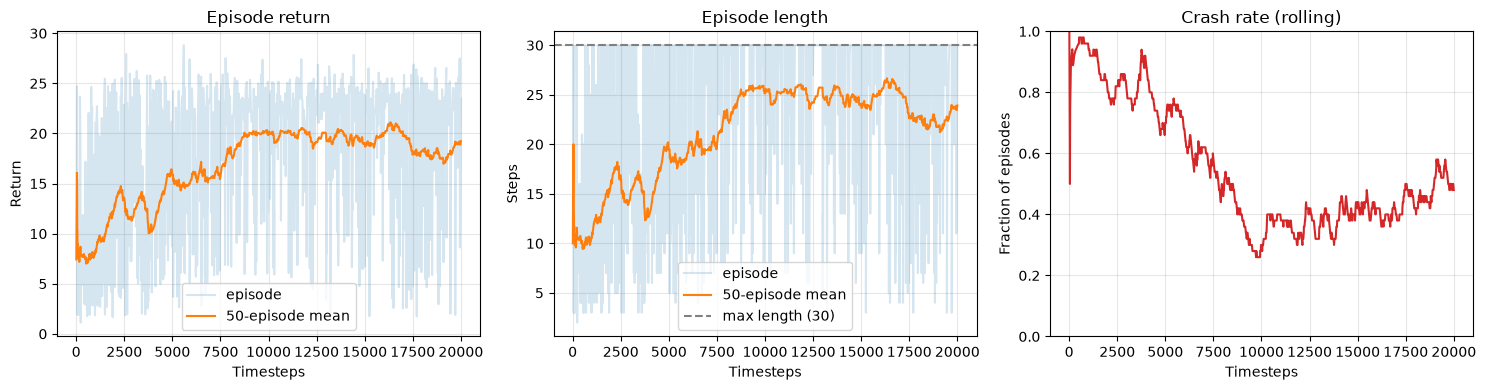

Episodes: 981
Final 50-episode mean return: 19.23
Final 50-episode mean length: 23.9
Final 50-episode crash rate: 48%


In [4]:
df = pd.DataFrame({
    "timestep": stats.timesteps,
    "return": stats.returns,
    "length": stats.lengths,
    "crashed": stats.crashes,
})

WINDOW = 50
df["return_ma"] = df["return"].rolling(WINDOW, min_periods=1).mean()
df["length_ma"] = df["length"].rolling(WINDOW, min_periods=1).mean()
df["crash_ma"] = df["crashed"].rolling(WINDOW, min_periods=1).mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(df["timestep"], df["return"], alpha=0.18, label="episode")
axes[0].plot(df["timestep"], df["return_ma"], label=f"{WINDOW}-episode mean")
axes[0].set_title("Episode return")
axes[0].set_xlabel("Timesteps")
axes[0].set_ylabel("Return")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(df["timestep"], df["length"], alpha=0.18, label="episode")
axes[1].plot(df["timestep"], df["length_ma"], label=f"{WINDOW}-episode mean")
axes[1].axhline(30, color="gray", linestyle="--", label="max length (30)")
axes[1].set_title("Episode length")
axes[1].set_xlabel("Timesteps")
axes[1].set_ylabel("Steps")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(df["timestep"], df["crash_ma"], color="C3")
axes[2].set_ylim(0, 1)
axes[2].set_title("Crash rate (rolling)")
axes[2].set_xlabel("Timesteps")
axes[2].set_ylabel("Fraction of episodes")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Episodes: {len(df)}")
print(f"Final {WINDOW}-episode mean return: {df['return_ma'].iloc[-1]:.2f}")
print(f"Final {WINDOW}-episode mean length: {df['length_ma'].iloc[-1]:.1f}")
print(f"Final {WINDOW}-episode crash rate: {df['crash_ma'].iloc[-1]:.0%}")

## 4. Evaluate the policy

In [5]:
N_EVAL_EPISODES = 100

eval_returns = []
eval_lengths = []
eval_crashes = []

for episode in range(N_EVAL_EPISODES):
    obs, info = env.reset(seed=episode)
    done = truncated = False
    episode_return = 0.0
    steps = 0
    crashed = False

    while not (done or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, done, truncated, info = env.step(action)
        episode_return += reward
        steps += 1
        crashed = crashed or info.get("crashed", False)

    eval_returns.append(episode_return)
    eval_lengths.append(steps)
    eval_crashes.append(crashed)

eval_df = pd.DataFrame({
    "return": eval_returns,
    "length": eval_lengths,
    "crashed": eval_crashes,
}, index=range(1, N_EVAL_EPISODES + 1))
eval_df.index.name = "episode"

print(f"Mean return: {np.mean(eval_returns):.2f}")
print(f"Mean length: {np.mean(eval_lengths):.2f} / 30")
print(f"Crash rate:  {np.mean(eval_crashes):.0%}")
eval_df

Mean return: 19.72
Mean length: 24.68 / 30
Crash rate:  32%


,return,length,crashed
episode,,,
1,23.886842,30,False
2,18.116630,24,True
3,5.067515,6,True
4,27.742487,30,False
5,22.446833,30,False
...,...,...,...
96,26.552932,30,False
97,25.886888,30,False
98,21.151394,27,True
